In [23]:
import pandas as pd
df = pd.read_csv("D:\\project 2\\rogue_access_point_dataset.csv")
print(df.head())

print(df.columns.tolist())

df = df.drop(columns=["BSSID"])
print(df.columns.tolist())


   Label Is_Duplication Distance_Level Encryption  Channel  Signal_Strength  \
0  Rogue            Yes           Near       WPA2        7              -49   
1  Legit             No         Medium       WPA2        2              -53   
2  Legit             No           Near       Open        1              -39   
3  Rogue            Yes            Far        WEP        1              -57   
4  Legit             No            Far       WPA2        6              -35   

               BSSID         SSID  
0  7A:E1:2A:A1:D3:57   Admin_WiFi  
1  9D:D7:26:11:22:A4  Smart_Class  
2  9D:9E:E5:BF:97:72   Library_AP  
3  4C:8E:A5:58:80:71      Cafe_AP  
4  C7:61:3B:92:36:8F  Hostel_WiFi  
['Label', 'Is_Duplication', 'Distance_Level', 'Encryption', 'Channel', 'Signal_Strength', 'BSSID', 'SSID']
['Label', 'Is_Duplication', 'Distance_Level', 'Encryption', 'Channel', 'Signal_Strength', 'SSID']


In [24]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

cols_to_encode = [
    "Is_Duplication",
    "Distance_Level",
    "Encryption",
    "SSID"
]

for col in cols_to_encode:
    df[col] = encoder.fit_transform(df[col])
    df["Label"] = LabelEncoder().fit_transform(df["Label"])
    print(df.head())

   Label  Is_Duplication Distance_Level Encryption  Channel  Signal_Strength  \
0      1               1           Near       WPA2        7              -49   
1      0               0         Medium       WPA2        2              -53   
2      0               0           Near       Open        1              -39   
3      1               1            Far        WEP        1              -57   
4      0               0            Far       WPA2        6              -35   

          SSID  
0   Admin_WiFi  
1  Smart_Class  
2   Library_AP  
3      Cafe_AP  
4  Hostel_WiFi  
   Label  Is_Duplication  Distance_Level Encryption  Channel  Signal_Strength  \
0      1               1               2       WPA2        7              -49   
1      0               0               1       WPA2        2              -53   
2      0               0               2       Open        1              -39   
3      1               1               0        WEP        1              -57   
4      0    

In [25]:
X = df.drop("Label", axis=1)
y = df["Label"]
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

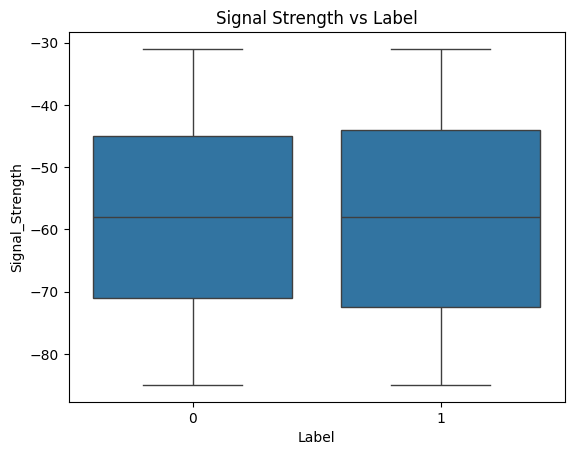

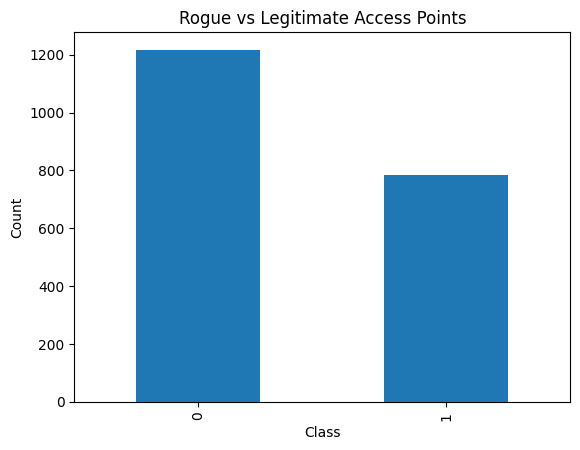

In [26]:
y.value_counts()
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(x=y, y=df["Signal_Strength"])
plt.title("Signal Strength vs Label")
plt.show()

y.value_counts().plot(kind="bar")
plt.xlabel("Class")
plt.ylabel("Count")
plt.title("Rogue vs Legitimate Access Points")
plt.show()


GridSearchCV is running...

Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation Accuracy:
1.0

Prediction completed!

Accuracy: 1.0
Accuracy (%): 100.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       243
           1       1.00      1.00      1.00       157

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400


Confusion Matrix:
[[243   0]
 [  0 157]]


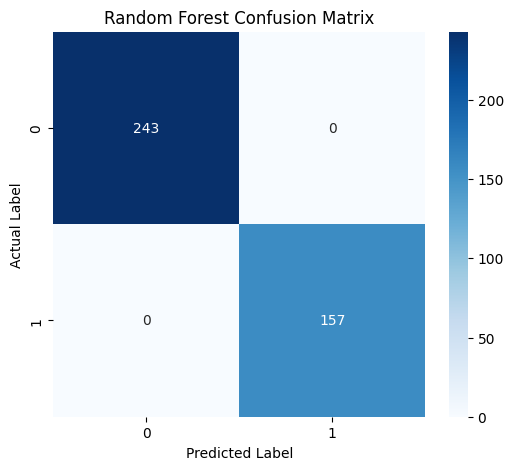


Feature Importance:
           Feature  Importance
0   Is_Duplication    0.961740
4  Signal_Strength    0.015495
3          Channel    0.008708
5             SSID    0.007126
2       Encryption    0.003694
1   Distance_Level    0.003238

Model saved successfully!


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

# Random Forest
rf = RandomForestClassifier(random_state=42)

# Grid Parameters
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10]
}

# GridSearchCV
grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("GridSearchCV is running...")

# Training
grid.fit(X_train, y_train)

# Best parameters
print("\nBest Parameters:")
print(grid.best_params_)

# Best CV score
print("\nBest Cross-Validation Accuracy:")
print(grid.best_score_)

# Best model
model = grid.best_estimator_

# Prediction
y_pred = model.predict(X_test)

print("\nPrediction completed!")

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")
plt.show()

# Feature Importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(feature_importance)

# Save Model
joblib.dump(
    model,
    r"D:\project 2\rogue_rf_model.pkl"
)

print("\nModel saved successfully!")

In [28]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

model = SVC()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6075


In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.72


In [30]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Confusion Matrix
[[204  39]
 [ 73  84]]

Classification Report
              precision    recall  f1-score   support

           0       0.74      0.84      0.78       243
           1       0.68      0.54      0.60       157

    accuracy                           0.72       400
   macro avg       0.71      0.69      0.69       400
weighted avg       0.72      0.72      0.71       400



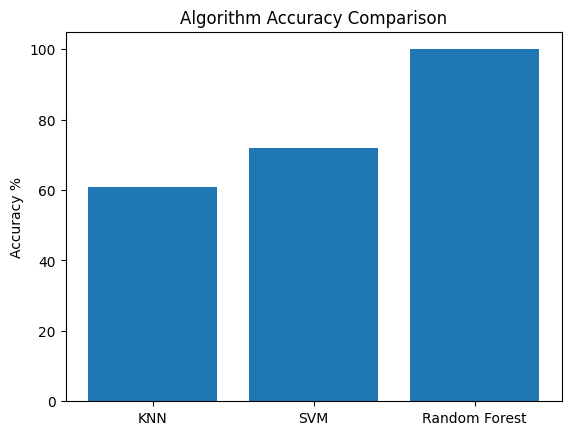

In [31]:
import matplotlib.pyplot as plt

algorithms = ["KNN","SVM","Random Forest"]
accuracy = [60.75,72,100]

plt.bar(algorithms,accuracy)
plt.title("Algorithm Accuracy Comparison")
plt.ylabel("Accuracy %")
plt.show()

In [32]:
import joblib

joblib.dump(best_model, r"D:\project 2\rogue_rf_model.pkl")

print("Model saved successfully")

Model saved successfully
